# GRZS v številkah / GRZS in numbers

**Letna statistika / Annual statistics**

Ta zvezek ponuja ponovljive preglede javno objavljene statistike intervencij Gorske reševalne zveze Slovenije (GRZS). Podatki so **letni seštevki po reševalnih enotah**, ne zapisi posameznih nesreč; z njimi ni mogoče raziskovati okoliščin posameznega dogodka.

This notebook provides reproducible views of the Slovenian Mountain Rescue Association (GRZS) published intervention statistics. The data are **annual aggregates by rescue unit**, not records of individual incidents; they cannot be used to investigate the circumstances of a particular event.

**Vir / Source:** [GRZS – Statistika nesreč](https://www.grzs.si/resevanje/statistika-nesrec/). Podatki v zvezku so lokalna kopija `data/accidents.csv`; zvezek jih ne prenaša in ne osvežuje samodejno. / Data in this notebook are the local `data/accidents.csv` snapshot; the notebook does not fetch or update data.

**Pomembno / Important:** zadnje leto v datoteki je lahko nepopolno. GRZS pojasnjuje, da so vključene zaključene intervencije oziroma popolna poročila, zato tekoče leto ni nujno primerljivo s polnimi leti. Pred uporabo preverite stanje in poimenovanje kategorij pri viru. / The latest year in the file may be incomplete. GRZS explains that statistics include concluded interventions or complete reports, so the current year may not be comparable with full years. Check the source's latest data and category definitions before use.

## 1. Naložite podatke / Load the data

Jupyter zaženite iz korenske mape projekta ali mape `notebooks`; pot do CSV se poišče v trenutni mapi in njenih nadrejenih mapah. Namestitev: `python -m pip install -r requirements-notebook.txt`.

Start Jupyter from the project root or the `notebooks` folder; the CSV is located by searching the current directory and its parents. Install dependencies with `python -m pip install -r requirements-notebook.txt`.

In [1]:
import csv
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / "data" / "accidents.csv").is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_PATH = PROJECT_ROOT / "data" / "accidents.csv"
if not DATA_PATH.is_file():
    raise FileNotFoundError("Could not find data/accidents.csv. Open this notebook from the project checkout.")

with DATA_PATH.open(encoding="utf-8", newline="") as csv_file:
    reader = csv.DictReader(csv_file)
    required_columns = {"year", "section", "unit", "metric", "value"}
    if not required_columns.issubset(reader.fieldnames or []):
        raise ValueError(f"CSV must contain columns {sorted(required_columns)}")
    rows = [
        {
            "year": int(row["year"]),
            "section": row["section"],
            "unit": row["unit"],
            "metric": row["metric"],
            "value": float(row["value"]),
        }
        for row in reader
    ]

if not rows:
    raise ValueError("The CSV contains no statistics.")
years = sorted({row["year"] for row in rows})
latest_year = years[-1]
reference_year = years[-2] if len(years) > 1 else latest_year
print(f"Loaded {len(rows):,} rows from {DATA_PATH}")

Loaded 14,652 rows from /Users/ajda/Source/Personal/GRZS-analiza/data/accidents.csv


## 2. Obseg, preverjanja in povzetek / Coverage, checks, and summary

Zneski spodaj so vsote objavljenih vrednosti po enotah znotraj kategorije. Kategorije iz različnih razdelkov niso nujno medsebojno izključujoče; ne seštevajte jih brez potrditve pri GRZS. / Totals below sum the published values across units within a category. Categories across sections are not necessarily mutually exclusive; do not add them together without confirmation from GRZS.

In [2]:
totals = defaultdict(float)
keys = []
for row in rows:
    key = (row["year"], row["section"], row["unit"], row["metric"])
    keys.append(key)
    if row["value"] < 0:
        raise ValueError(f"Unexpected negative value: {row}")
    totals[(row["year"], row["section"], row["metric"])] += row["value"]

print(f"Years / Leta: {years[0]}–{latest_year} ({len(years)} distinct years)")
print(f"Rescue units / Reševalne enote: {len({row['unit'] for row in rows})}")
print(f"Sections / Razdelki: {', '.join(sorted({row['section'] for row in rows}))}")
print(f"Duplicate year-section-unit-metric rows / Podvojene vrstice: {len(keys) - len(set(keys))}")
print(f"Latest year / Zadnje leto: {latest_year} — potentially incomplete / lahko nepopolno")
if len(years) > 1:
    print(f"Reference year / Primerjalno leto: {reference_year} — verify completeness at source / preverite popolnost pri viru")

completed = {year: totals.get((year, "intervencije", "zakljucene"), 0) for year in years}
if len(years) > 1 and completed[years[0]]:
    start, end = years[0], reference_year
    change = completed[end] - completed[start]
    percent = 100 * change / completed[start]
    print(
        f"Summary / Povzetek: completed interventions / zaključene intervencije "
        f"{start}→{end}: {completed[start]:,.0f}→{completed[end]:,.0f} "
        f"({change:+,.0f}; {percent:+.1f}%). This is a count trend, not a rate or explanation of cause. "
        f"/ To je trend števila, ne stopnja ali razlaga vzroka."
    )
else:
    print("Not enough comparable years for a trend / Ni dovolj primerljivih let za trend.")

if len(keys) != len(set(keys)):
    raise ValueError("Duplicate year-section-unit-metric rows found; inspect the source before analysis.")

Years / Leta: 2006–2026 (21 distinct years)
Rescue units / Reševalne enote: 18
Sections / Razdelki: akcijaTip, dejavnost, intervencije, poskodbaVrsta, poskodovanecStarost
Duplicate year-section-unit-metric rows / Podvojene vrstice: 0
Latest year / Zadnje leto: 2026 — potentially incomplete / lahko nepopolno
Reference year / Primerjalno leto: 2025 — verify completeness at source / preverite popolnost pri viru
Editorial lead / Uredniški namig: completed interventions / zaključene intervencije 2006→2025: 292→658 (+366; +125.3%). This is a count trend, not a rate or explanation of cause. / To je trend števila, ne stopnja ali razlaga vzroka.


## 3. Intervencije po letih / Interventions by year

`zakljucene` pomeni zaključene, `obdelava` obdelavo, `vse` pa skupno objavljeno vrednost. Prikazujemo zaključene in skupne vrednosti ločeno; zadnje leto je označeno kot morebitno nepopolno. / `zakljucene` means concluded, `obdelava` means being processed, and `vse` is the published total. Concluded and total values are shown separately; the latest year is marked as potentially incomplete.

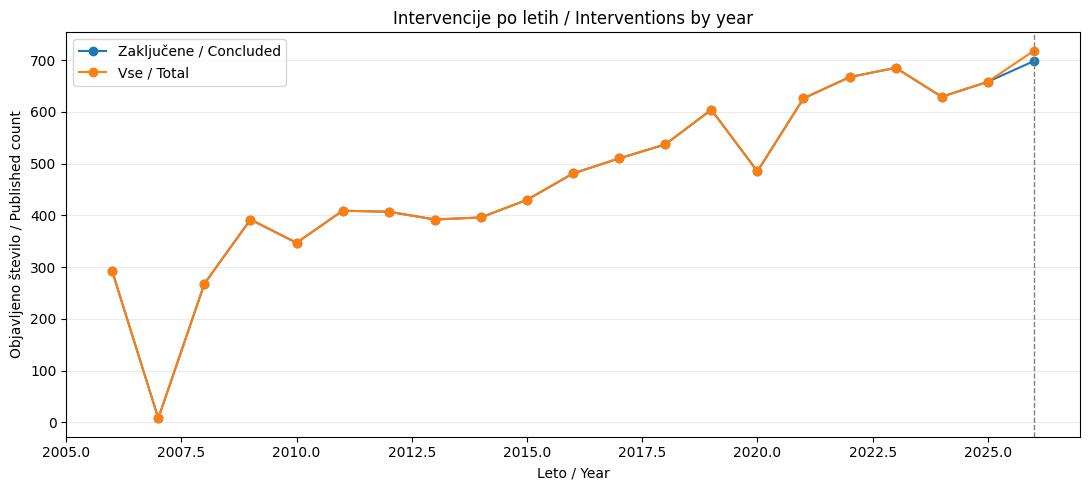

In [3]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(years, [totals.get((year, "intervencije", "zakljucene"), 0) for year in years], marker="o", label="Zaključene / Concluded")
ax.plot(years, [totals.get((year, "intervencije", "vse"), 0) for year in years], marker="o", label="Vse / Total")
ax.axvline(latest_year, color="grey", linestyle="--", linewidth=1)
ax.set(title="Intervencije po letih / Interventions by year", xlabel="Leto / Year", ylabel="Objavljeno število / Published count")
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

## 4. Dejavnosti / Activities

Prikazane so dejavnosti z največjim seštevkom v vseh letih, ne deleži vseh intervencij. Ena intervencija se lahko pojavi v več kategorijah dejavnosti. / The chart shows activities with the largest sum across all years, not shares of all interventions. One intervention may appear in multiple activity categories.

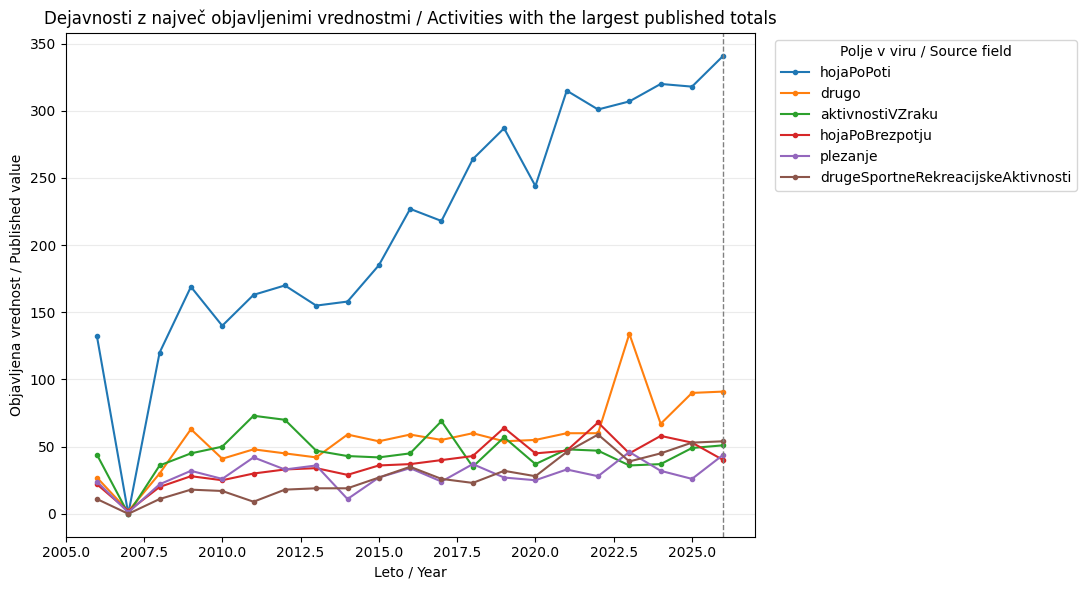

Source field names are retained because translations/definitions should be verified with GRZS. / Imena polj ohranjamo, ker je treba prevode in definicije preveriti pri GRZS.


In [4]:
activity_metrics = sorted({row["metric"] for row in rows if row["section"] == "dejavnost"})
activity_totals = {
    metric: sum(totals.get((year, "dejavnost", metric), 0) for year in years)
    for metric in activity_metrics
}
top_activities = sorted(activity_metrics, key=activity_totals.get, reverse=True)[:6]
fig, ax = plt.subplots(figsize=(11, 6))
for metric in top_activities:
    ax.plot(years, [totals.get((year, "dejavnost", metric), 0) for year in years], marker=".", label=metric)
ax.axvline(latest_year, color="grey", linestyle="--", linewidth=1)
ax.set(title="Dejavnosti z največ objavljenimi vrednostmi / Activities with the largest published totals", xlabel="Leto / Year", ylabel="Objavljena vrednost / Published value")
ax.legend(title="Polje v viru / Source field", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()
print("Source field names are retained because translations/definitions should be verified with GRZS. / Imena polj ohranjamo, ker je treba prevode in definicije preveriti pri GRZS.")

## 5. Vrste reševalnih akcij / Rescue-action categories

Polja iz izvornega razdelka `akcijaTip` so prikazana ločeno. `resevalcev` je objavljeno polje in ga ne smemo zamenjati s številom intervencij. Kategorije morda niso izključujoče. / Fields from the source section `akcijaTip` are shown separately. `resevalcev` is a published field and should not be mistaken for the number of interventions. Categories may overlap.

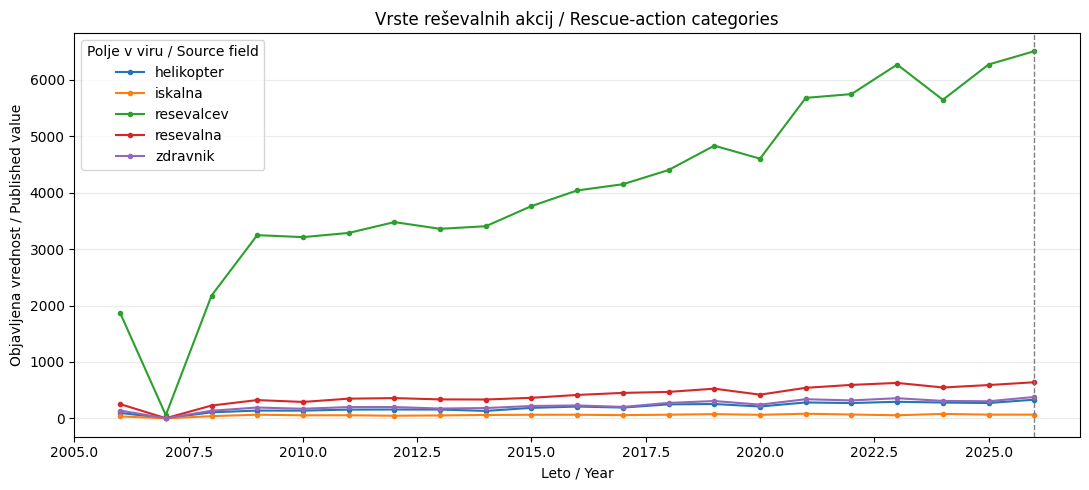

In [5]:
action_metrics = sorted({row["metric"] for row in rows if row["section"] == "akcijaTip"})
fig, ax = plt.subplots(figsize=(11, 5))
for metric in action_metrics:
    ax.plot(years, [totals.get((year, "akcijaTip", metric), 0) for year in years], marker=".", label=metric)
ax.axvline(latest_year, color="grey", linestyle="--", linewidth=1)
ax.set(title="Vrste reševalnih akcij / Rescue-action categories", xlabel="Leto / Year", ylabel="Objavljena vrednost / Published value")
ax.legend(title="Polje v viru / Source field")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

## 6. Vrste poškodb in starost / Outcomes and age groups

Razčlenitve prikazujejo objavljene kategorije, brez sklepanja o vzroku. Imena polj so namenoma ohranjena v izvirni obliki, kjer bi prevod lahko napačno nakazal pomen. / These breakdowns show published categories without inferring cause. Source field names are retained where a translation could imply an unverified meaning.

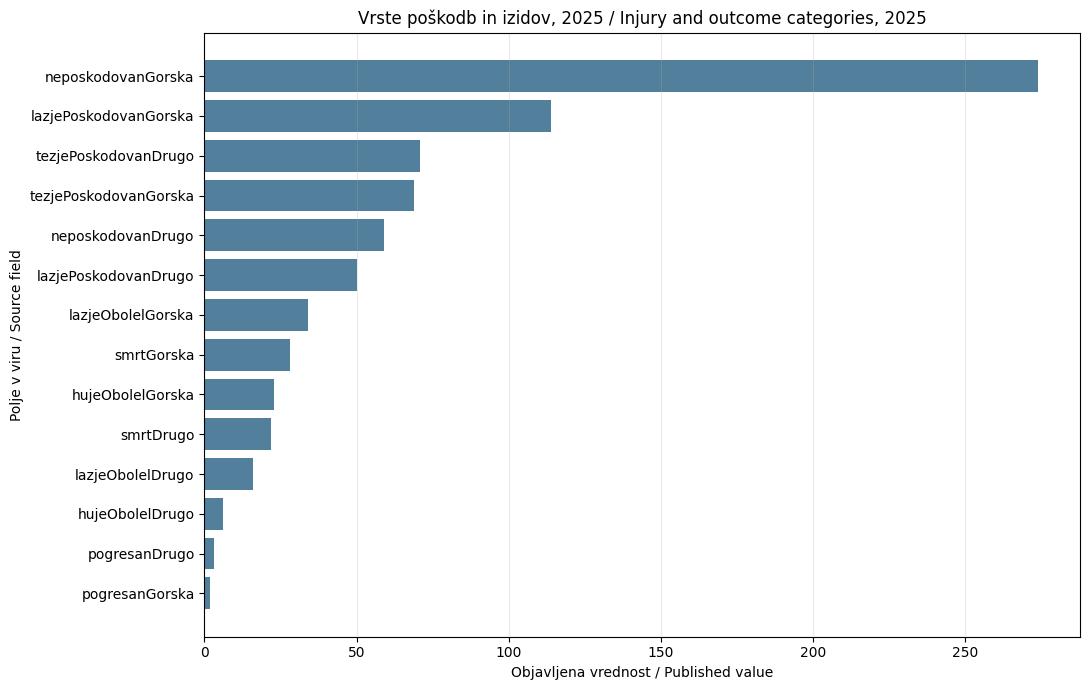

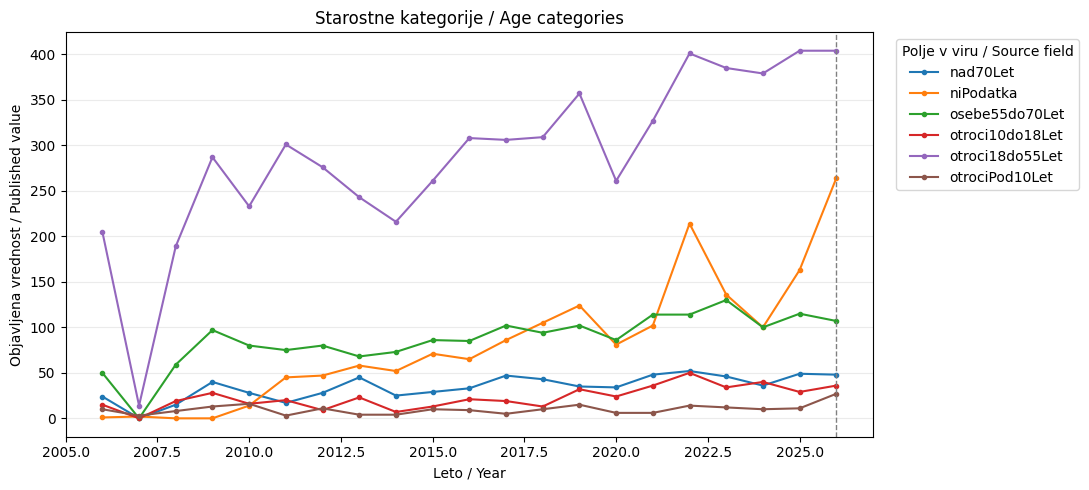

Check source definitions for each category, especially unknown/missing values. / Pri viru preverite definicije kategorij, zlasti vrednosti za neznano oziroma manjkajoče podatke.


In [6]:
outcome_metrics = sorted({row["metric"] for row in rows if row["section"] == "poskodbaVrsta"})
outcome_totals = {metric: totals.get((reference_year, "poskodbaVrsta", metric), 0) for metric in outcome_metrics}
ordered_outcomes = sorted(outcome_metrics, key=outcome_totals.get)
fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(ordered_outcomes, [outcome_totals[metric] for metric in ordered_outcomes], color="#527f9b")
ax.set(title=f"Vrste poškodb in izidov, {reference_year} / Injury and outcome categories, {reference_year}", xlabel="Objavljena vrednost / Published value", ylabel="Polje v viru / Source field")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

age_metrics = sorted({row["metric"] for row in rows if row["section"] == "poskodovanecStarost"})
fig, ax = plt.subplots(figsize=(11, 5))
for metric in age_metrics:
    ax.plot(years, [totals.get((year, "poskodovanecStarost", metric), 0) for year in years], marker=".", label=metric)
ax.axvline(latest_year, color="grey", linestyle="--", linewidth=1)
ax.set(title="Starostne kategorije / Age categories", xlabel="Leto / Year", ylabel="Objavljena vrednost / Published value")
ax.legend(title="Polje v viru / Source field", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()
print("Check source definitions for each category, especially unknown/missing values. / Pri viru preverite definicije kategorij, zlasti vrednosti za neznano oziroma manjkajoče podatke.")

## 7. Primerjava reševalnih enot / Comparing rescue units

Prikazanih je največ deset enot po objavljeni vrednosti `intervencije.vse` za primerjalno leto (leto pred zadnjim v datoteki). To ni lestvica kakovosti ali tveganja: enote pokrivajo različna območja, obseg obiskovalcev in okoliščine niso upoštevani, primerjalno leto pa je treba preveriti. / The chart shows up to ten units by the published `intervencije.vse` value for the reference year (the year before the latest in the file). This is not a ranking of performance or risk: units cover different areas, visitor exposure and circumstances are not accounted for, and the reference year should be verified.

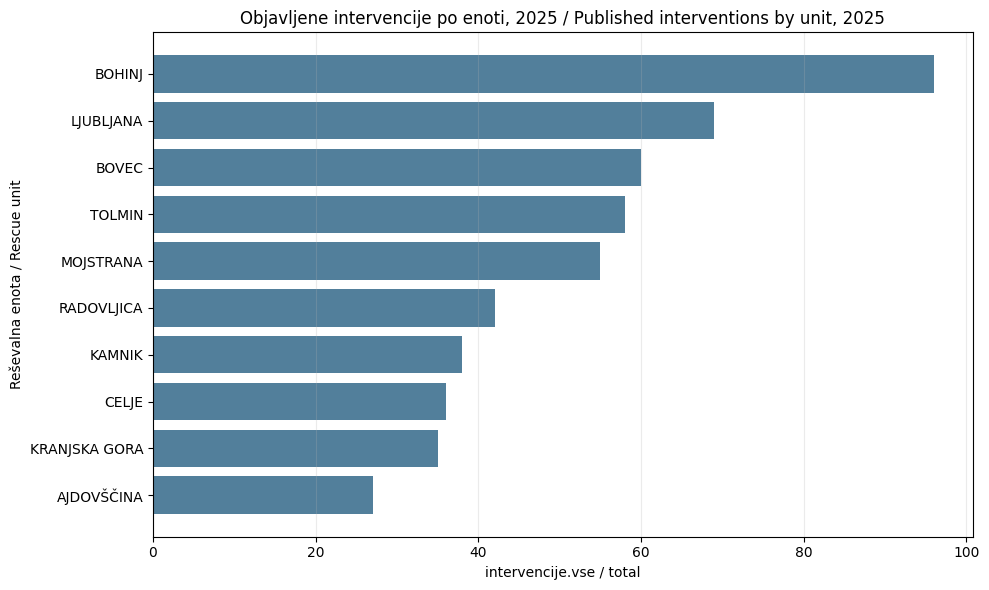

In [7]:
unit_totals = defaultdict(float)
for row in rows:
    if row["year"] == reference_year and row["section"] == "intervencije" and row["metric"] == "vse":
        unit_totals[row["unit"]] += row["value"]
top_units = sorted(unit_totals.items(), key=lambda item: item[1])[-10:]
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh([unit for unit, _ in top_units], [value for _, value in top_units], color="#527f9b")
ax.set(title=f"Objavljene intervencije po enoti, {reference_year} / Published interventions by unit, {reference_year}", xlabel="intervencije.vse / total", ylabel="Reševalna enota / Rescue unit")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

## 8. Odgovorna uporaba / Responsible use

- **Povejte, kaj štejejo podatki:** letni agregati GRZS po enotah in kategorijah, ne posamezni primeri. / **Say what the data count:** annual GRZS aggregates by unit and category, not individual cases.
- **Preverite popolnost zadnjega leta** pri GRZS; primerjajte enako dolga obdobja ali izločite nepopolno leto. / **Verify the latest year's completeness** with GRZS; compare equal periods or exclude an incomplete year.
- **Ne sklepajte o vzrokih, tveganju ali uspešnosti** iz samih števil intervencij. Manjkajo imenovalci in okoliščine. / **Do not infer causes, risk, or performance** from intervention counts alone. Denominators and circumstances are missing.
- **Ne seštevajte kategorij kot neodvisnih dogodkov** brez potrditve, da se ne prekrivajo; preverite tudi definicije polj in morebitne spremembe metodologije pri viru. / **Do not add categories as independent events** unless their mutual exclusivity is confirmed; check field definitions and any methodology changes with the source.
- **Navedite vir in datum prenosa** (`data/accidents.csv` je posnetek), po potrebi pa delite izračun in graf za ponovljivost. / **Cite the source and retrieval date** (`data/accidents.csv` is a snapshot), and share the calculation and chart where useful for reproducibility.

Za osvežitev podatkov uporabite `python3 scripts/fetch_stats.py`; nato znova zaženite vse celice. / To refresh the data, run `python3 scripts/fetch_stats.py`, then rerun all cells.